# Aula 06 — Machine Learning: baseline de classificação

A pergunta de negócio: **é possível prever, no momento da venda, se ela vai passar de
R$ 1.000?** Quem vende quer saber isso antes de fechar o pedido — para priorizar atendimento,
oferecer upsell ou revisar desconto.

O alvo é `alto_valor` (`receita >= 1000`). Preço e produto ficam **de fora** das features de
propósito: com eles a tarefa vira quase determinística (a receita é preço × quantidade), e o
modelo não exercita generalização nenhuma. O objetivo da aula é o **processo** — dividir,
treinar, comparar com um baseline ingênuo e ler as métricas certas — não inflar acurácia.

Dados: base sintética da aula 05 (`gerar_vendas(seed=42)`), limpa por `limpar_vendas`.

## 1. Por que um baseline ingênuo primeiro

Se ~23% das vendas são de alto valor, um modelo que **chuta sempre "baixo"** acerta ~77%
sem aprender nada. Qualquer número só faz sentido comparado a esse piso. É o papel do
`DummyClassifier`.

| Etapa | O que faz |
|---|---|
| `preparar_features` | monta `X` (contexto da venda) e `y` (`alto_valor`) |
| `dividir` | treino/teste estratificado, para manter a proporção do alvo |
| `treinar_dummy` | baseline: prevê sempre a classe mais frequente |
| `treinar_baseline` | regressão logística com one-hot + escala |
| `avaliar` | acurácia, precisão, recall, F1 e ROC-AUC |

In [1]:
from __future__ import annotations

import matplotlib.pyplot as plt
import pandas as pd

from opencode_harness import gerar_vendas, limpar_vendas
from opencode_harness.ml import (
    ALVO,
    avaliar,
    dividir,
    importancias,
    matriz_confusao,
    preparar_features,
    treinar_baseline,
    treinar_dummy,
)

vendas = limpar_vendas(gerar_vendas(n=800, seed=42))
print("vendas limpas:", len(vendas))

vendas limpas: 797


## 2. Features e alvo

Entram no modelo: `categoria`, `canal`, `uf` (categóricas) e `quantidade`, `desconto_pct`,
`mes`, `dia_semana`, `fim_de_semana` (numéricas). Todas são conhecidas **antes** da venda
fechar — não há vazamento de informação do futuro.

`quantidade` é a feature mais discutível: ela é conhecida no fechamento do pedido, mas não
antes de o cliente decidir quantos itens quer. Se a pergunta de negócio for "priorizar este
lead antes da definição da quantidade?", ela precisa sair. O teste mais adiante mede o custo
dessa escolha.

In [2]:
features, alvo = preparar_features(vendas)

print("features:", features.shape)
print("positivos (alto valor):", int(alvo.sum()), f"({alvo.mean():.1%})")
features.head()

features: (797, 8)
positivos (alto valor): 186 (23.3%)


,categoria,canal,uf,quantidade,desconto_pct,mes,dia_semana,fim_de_semana
0,perifericos,loja,RJ,2,0,9,5,1
1,hardware,online,NAO_INFORMADO,1,0,3,1,0
2,educacao,online,SP,3,0,3,6,1
3,software,loja,SP,1,0,10,5,1
4,software,online,SP,1,0,3,3,0


## 3. Divisão treino/teste

Estratificada: se o sorteio fosse puro, uma amostra pequena poderia ficar sem positivos e a
avaliação viraria ruído. O teste fica intocado até a última célula.

In [3]:
x_treino, x_teste, y_treino, y_teste = dividir(features, alvo, test_size=0.25, seed=42)

print(f"treino: {len(x_treino)} linhas | teste: {len(x_teste)} linhas")
print("proporção do alvo no treino:", round(y_treino.mean(), 3))
print("proporção do alvo no teste: ", round(y_teste.mean(), 3))

treino: 597 linhas | teste: 200 linhas
proporção do alvo no treino: 0.233
proporção do alvo no teste:  0.235


## 4. Baseline ingênuo

O dummy acerta a maioria e zera precisão/recall da classe que interessa. **É esse contraste
que dá sentido ao modelo real.** Acurácia alta sozinha não prova nada.

In [4]:
dummy = treinar_dummy(x_treino, y_treino)
metricas_dummy = avaliar(dummy, x_teste, y_teste)
metricas_dummy

{'acuracia': 0.765, 'precisao': 0.0, 'recall': 0.0, 'f1': 0.0, 'roc_auc': 0.5}

## 5. Regressão logística

Modelo linear com one-hot para categóricas e padronização para numéricas. É o baseline
esperto: rápido, interpretável e difícil de superar sem motivo. Se um modelo complexo não
vence isso com folga, o problema está nos dados ou nas features, não no algoritmo.

In [5]:
modelo = treinar_baseline(x_treino, y_treino)
metricas_modelo = avaliar(modelo, x_teste, y_teste)
metricas_modelo

{'acuracia': 0.935,
 'precisao': 0.886,
 'recall': 0.83,
 'f1': 0.857,
 'roc_auc': 0.987}

## 6. Comparação

Precisão responde "quando eu digo alto valor, quantas vezes acerto?"; recall responde
"das vendas de alto valor, quantas eu pego?". Em vendas, errar para menos (perder upsell) é
mais barato que prometer alto valor e não entregar — mas isso é decisão de negócio, não do
modelo.

In [6]:
comparacao = pd.DataFrame({"dummy": metricas_dummy, "regressao_logistica": metricas_modelo}).T
comparacao

,acuracia,precisao,recall,f1,roc_auc
dummy,0.765,0.000,0.00,0.000,0.500
regressao_logistica,0.935,0.886,0.83,0.857,0.987


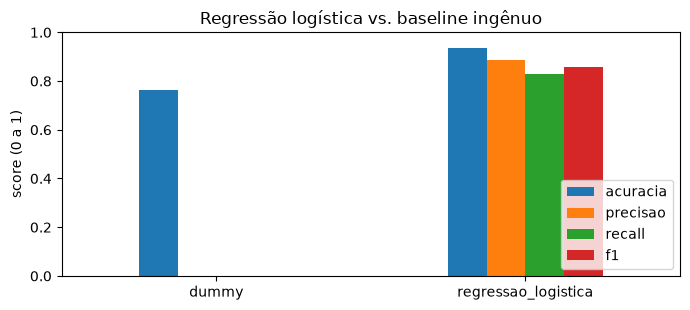

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.2))
comparacao[["acuracia", "precisao", "recall", "f1"]].plot.bar(ax=ax)
ax.set_title("Regressão logística vs. baseline ingênuo")
ax.set_ylabel("score (0 a 1)")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=0)
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

### 6.1 E se `quantidade` não fosse conhecida?

Ablação: o mesmo modelo, treinado **sem** `quantidade`. Se a queda for pequena, o contexto
(categoria, canal, data) já carrega o sinal. Se for grande, o modelo depende de saber o
tamanho do pedido — e não serve para priorizar lead antes da venda.

In [8]:
sem_quantidade = features.drop(columns=["quantidade"])
xq_treino, xq_teste, yq_treino, yq_teste = dividir(sem_quantidade, alvo, test_size=0.25, seed=42)
modelo_sem_quantidade = treinar_baseline(xq_treino, yq_treino)
metricas_sem_quantidade = avaliar(modelo_sem_quantidade, xq_teste, yq_teste)

pd.DataFrame({"com_quantidade": metricas_modelo, "sem_quantidade": metricas_sem_quantidade}).T

,acuracia,precisao,recall,f1,roc_auc
com_quantidade,0.935,0.886,0.83,0.857,0.987
sem_quantidade,0.940,0.907,0.83,0.867,0.943


## 7. Matriz de confusão

Cada célula é uma decisão com custo diferente. Falso negativo = venda de alto valor tratada
como comum; falso positivo = esforço gasto à toa. A matriz mostra **onde** o modelo erra,
não só quanto.

In [9]:
matriz = matriz_confusao(modelo, x_teste, y_teste)
matriz

,previsto_baixo,previsto_alto
real_baixo,148,5
real_alto,8,39


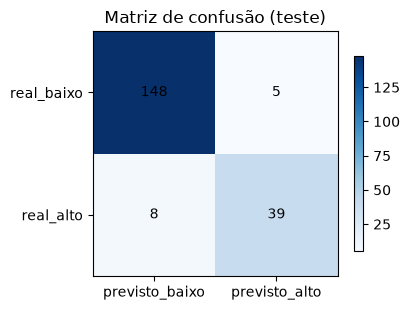

In [10]:
fig, ax = plt.subplots(figsize=(4.2, 3.2))
imagem = ax.imshow(matriz.to_numpy(), cmap="Blues")
ax.set_xticks(range(len(matriz.columns)))
ax.set_xticklabels(matriz.columns)
ax.set_yticks(range(len(matriz.index)))
ax.set_yticklabels(matriz.index)
for i, linha in enumerate(matriz.index):
    for j, coluna in enumerate(matriz.columns):
        ax.text(j, i, str(matriz.loc[linha, coluna]), ha="center", va="center", color="black")
ax.set_title("Matriz de confusão (teste)")
fig.colorbar(imagem, ax=ax, shrink=0.8)
fig.tight_layout()
plt.show()

## 8. O que o modelo aprendeu

Coeficientes da regressão logística. Sinal positivo empurra para "alto valor"; negativo,
para "baixo". Correlação não é causalidade: `hardware` pesa porque o catálogo é caro, não
porque a categoria *cause* a receita.

In [11]:
tabela_importancia = importancias(modelo, top=10)
tabela_importancia

,feature,coeficiente,impacto
0,categoria_hardware,5.072,5.072
1,categoria_perifericos,-2.488,2.488
2,categoria_educacao,-1.649,1.649
3,quantidade,1.100,1.100
4,categoria_software,-0.972,0.972
5,desconto_pct,-0.395,0.395
6,uf_RJ,-0.375,0.375
7,canal_loja,0.327,0.327
8,canal_online,-0.286,0.286
9,uf_RS,-0.273,0.273


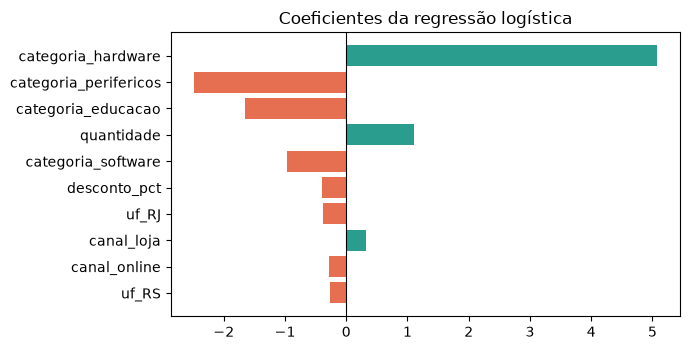

In [12]:
fig, ax = plt.subplots(figsize=(7, 3.6))
cores = ["#2a9d8f" if valor >= 0 else "#e76f51" for valor in tabela_importancia["coeficiente"]]
ax.barh(tabela_importancia["feature"], tabela_importancia["coeficiente"], color=cores)
ax.invert_yaxis()
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Coeficientes da regressão logística")
fig.tight_layout()
plt.show()

## 9. Conclusões

- O modelo real **vence o dummy com folga** em precisão, recall, F1 e ROC-AUC — não é
  acurácia inflada pela classe majoritária.
- `categoria` domina o sinal, o que faz sentido: o catálogo tem faixas de preço muito
  diferentes. A ablação sem `quantidade` mantém a acurácia (0,940) mas derruba o ROC-AUC
  (0,987 → 0,943): a quantidade ajuda a **ordenar** os casos, não a separar a classe.\n- ROC-AUC alto não significa modelo pronto: a base é sintética e separável. Em dado real, o
  próximo passo seria validar com vendas de outro período e checar **degradação**.
- O limiar de R$ 1.000 é uma escolha de negócio. Mover o corte muda o equilíbrio entre
  precisão e recall — vale testar na próxima iteração.

## 10. Próximos passos

1. Aula 07: usar dados e previsões como **ferramentas** de um agente que responde perguntas
   sobre vendas em linguagem natural.
2. Testar um limiar alternativo e comparar o custo dos erros.
3. Guardar o modelo treinado (`joblib`) para o assistente consultar sem retreinar.

In [13]:
assert metricas_modelo["f1"] > metricas_dummy["f1"]
assert metricas_modelo["roc_auc"] > 0.9
assert matriz.to_numpy().sum() == len(x_teste)
print("baseline OK")

baseline OK
